In [30]:
suppressMessages(library(ggplot2))
suppressMessages(library(cowplot))
suppressMessages(library(dplyr))
suppressMessages(library(apeglm))
suppressMessages(library(ggrepel))
suppressMessages(library(ComplexHeatmap))

In [31]:
df_ln1 <- read.csv("../../results/02_10x_visium/03_de_analysis/de_results_LN_vs_Normal.csv", row.names = 1)
df_ln2 <- read.csv("../../results/10_compare_with_public_data/06_de_analysis/de_results_LN_vs_Normal.csv", row.names = 1)

In [32]:
head(df_ln1)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SAMD11,405.83041,-0.66105850,0.3819679,-1.7306651,8.351151e-02,1.466859e-01
NOC2L,617.15059,0.09908423,0.2428322,0.4080359,6.832474e-01,7.654096e-01
KLHL17,268.12514,-0.06516098,0.2195477,-0.2967964,7.666219e-01,8.295658e-01
PLEKHN1,149.40354,0.19147909,0.3206932,0.5970787,5.504548e-01,6.507080e-01
PERM1,64.75324,-1.71080278,0.3516677,-4.8648274,1.145567e-06,2.437084e-05
HES4,805.42255,-1.02845508,0.3212461,-3.2014557,1.367351e-03,5.567335e-03


In [33]:
head(df_ln2)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RP11-34P13.7,92.76376,2.6339751,0.7411606,3.5538518,0.000379633,0.002789608
FO538757.2,1036.80332,-3.7261956,1.6269515,-2.2902930,0.022004340,0.062055741
AP006222.2,163.62446,-0.1524176,0.3117304,-0.4889405,0.624883803,0.686907009
RP4-669L17.10,20.33234,0.9371157,0.7177401,1.3056477,0.191672375,0.284067787
RP5-857K21.4,1040.33524,-0.1666764,0.3555731,-0.4687542,0.639245336,0.699799878
RP11-206L10.9,468.21209,-0.6471602,0.8403474,-0.7701104,0.441234428,0.521215981


In [34]:
sel_genes <- intersect(rownames(df_ln1), rownames(df_ln2))
length(sel_genes)

[1] 13566

In [35]:
df_ln1 <- df_ln1[sel_genes, ]
df_ln2 <- df_ln2[sel_genes, ]

In [36]:
head(df_ln1)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SAMD11,405.8304,-0.66105850,0.3819679,-1.7306651,0.08351151,0.14668589
NOC2L,617.1506,0.09908423,0.2428322,0.4080359,0.68324735,0.76540962
KLHL17,268.1251,-0.06516098,0.2195477,-0.2967964,0.76662192,0.82956581
PLEKHN1,149.4035,0.19147909,0.3206932,0.5970787,0.55045485,0.65070800
ISG15,1139.1383,1.59520474,0.8205765,1.9440049,0.05189486,0.09979781
AGRN,5159.0950,0.28309543,0.2929886,0.9662337,0.33392723,0.44230427


In [37]:
head(df_ln2)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SAMD11,71.99613,-0.0484605,0.6581177,-0.07363501,0.9413008128,0.954133878
NOC2L,352.46637,-1.1339600,0.6536532,-1.73480372,0.0827755771,0.163566246
KLHL17,96.94046,-2.6895851,1.7897855,-1.50274159,0.1329056934,0.223301728
PLEKHN1,23.20198,2.5265275,0.6908258,3.65725686,0.0002549289,0.002112552
ISG15,62.98132,1.9078561,0.5940239,3.21174994,0.0013192916,0.006994317
AGRN,499.92965,-1.7482834,0.8313526,-2.10293849,0.0354711465,0.089227117


In [38]:
up_ln1 <- df_ln1 %>%
    subset(log2FoldChange > 1 & padj < 0.05) %>%
    rownames()

up_ln2 <- df_ln2 %>%
    subset(log2FoldChange > 1 & padj < 0.05) %>%
    rownames()

down_ln1 <- df_ln1 %>%
    subset(log2FoldChange < -1 & padj < 0.05) %>%
    rownames()

down_ln2 <- df_ln2 %>%
    subset(log2FoldChange < -1 & padj < 0.05) %>%
    rownames()

In [39]:
# group by condition and gene and convert to list, using condition as names
lt = list()

lt[["LN_UP_Ours"]] = up_ln1
lt[["LN_UP_JASN_2026"]] = up_ln2
lt[["LN_DOWN_Ours"]] = down_ln1
lt[["LN_DOWN_JASN_2026"]] = down_ln2

In [40]:
m = make_comb_mat(lt)

ss = set_size(m)
cs = comb_size(m)

In [41]:
ht <- UpSet(m, 
            set_order = order(ss), 
            comb_order = order(comb_degree(m), -cs), 
            show_row_names = FALSE,
            top_annotation = HeatmapAnnotation(
                "Intersections" = anno_barplot(cs, 
                ylim = c(0, max(cs)*1.1),
                border = FALSE, 
                gp = gpar(fill = "#8dd3c7"), 
                height = unit(4, "cm")
            ), 
            annotation_name_side = "left", 
            annotation_name_rot = 90),
            left_annotation = rowAnnotation(
                "Number of genes" = anno_barplot(-ss, 
                baseline = 0,
                 axis_param = list(
                at = c(0, -1000, -2000, -3000),
                labels = c(0, 1000, 2000, 3000),
                labels_rot = 0),
                border = FALSE, 
                gp = gpar(fill = "#8dd3c7"), 
                width = unit(4, "cm")
            ),
        set_name = anno_text(set_name(m), 
            location = 0.5, 
            just = "center",
            width = max_text_width(set_name(m)) + unit(4, "mm"))
    ), )

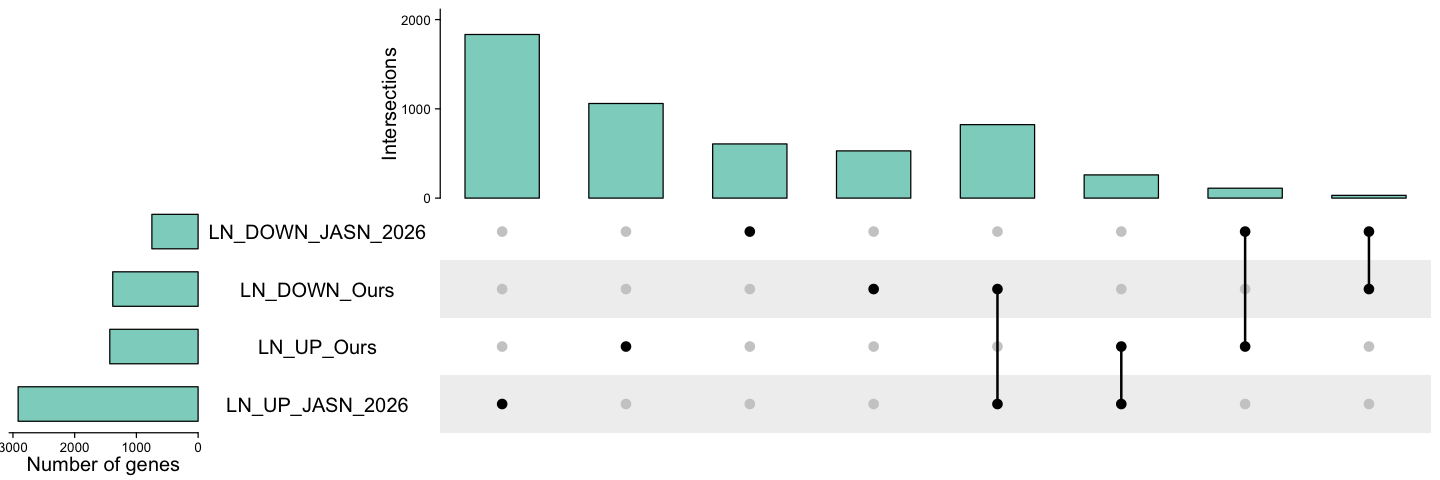

In [42]:
options(repr.plot.width=12, repr.plot.height=4)

ht <- draw(ht)

In [43]:
head(df_ln1)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SAMD11,405.8304,-0.66105850,0.3819679,-1.7306651,0.08351151,0.14668589
NOC2L,617.1506,0.09908423,0.2428322,0.4080359,0.68324735,0.76540962
KLHL17,268.1251,-0.06516098,0.2195477,-0.2967964,0.76662192,0.82956581
PLEKHN1,149.4035,0.19147909,0.3206932,0.5970787,0.55045485,0.65070800
ISG15,1139.1383,1.59520474,0.8205765,1.9440049,0.05189486,0.09979781
AGRN,5159.0950,0.28309543,0.2929886,0.9662337,0.33392723,0.44230427


In [44]:
head(df_ln2)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SAMD11,71.99613,-0.0484605,0.6581177,-0.07363501,0.9413008128,0.954133878
NOC2L,352.46637,-1.1339600,0.6536532,-1.73480372,0.0827755771,0.163566246
KLHL17,96.94046,-2.6895851,1.7897855,-1.50274159,0.1329056934,0.223301728
PLEKHN1,23.20198,2.5265275,0.6908258,3.65725686,0.0002549289,0.002112552
ISG15,62.98132,1.9078561,0.5940239,3.21174994,0.0013192916,0.006994317
AGRN,499.92965,-1.7482834,0.8313526,-2.10293849,0.0354711465,0.089227117


In [45]:
df_ln1 <- df_ln1[c("log2FoldChange")]
df_ln2 <- df_ln2[c("log2FoldChange")]

In [46]:
colnames(df_ln1) <- "log2FC_Ours"
colnames(df_ln2) <- "log2FC_JASN_2026"

In [47]:
df <- cbind(df_ln1, df_ln2)

In [48]:
head(df)

,log2FC_Ours,log2FC_JASN_2026
,<dbl>,<dbl>
SAMD11,-0.66105850,-0.0484605
NOC2L,0.09908423,-1.1339600
KLHL17,-0.06516098,-2.6895851
PLEKHN1,0.19147909,2.5265275
ISG15,1.59520474,1.9078561
AGRN,0.28309543,-1.7482834


In [49]:
p <- ggplot(data = df, aes(x = log2FC_Ours, y = log2FC_JASN_2026)) +
    geom_point(alpha = 0.5) +
    theme_bw() +
    xlab("log2 Fold Change (Ours)") +
    ylab("log2 Fold Change (JASN 2026)") +
    ggtitle("Comparison of log2 Fold Changes between Ours and JASN 2026") +
    theme(plot.title = element_text(hjust = 0.5)) +
    theme_cowplot()

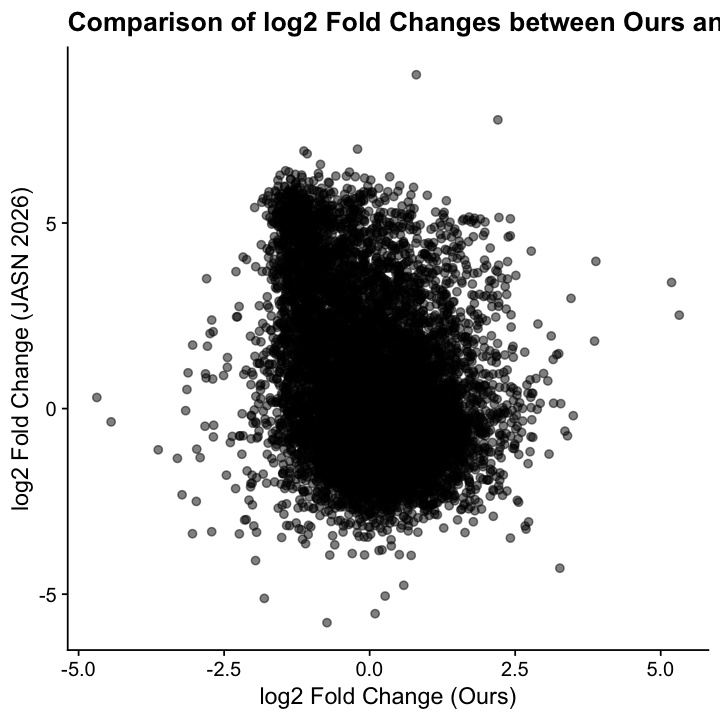

In [50]:
options(repr.plot.width=6, repr.plot.height=6)

p

In [54]:
cor(df$log2FC_Ours, df$log2FC_JASN_2026, method = "pearson")

[1] -0.3002543

In [51]:
df['VAT1', ]

,log2FC_Ours,log2FC_JASN_2026
,<dbl>,<dbl>
VAT1,2.097495,0.3480279
